# 5. Étude comparative des prédictions

Objectif : comparer en détail les deux modèles entraînés à l'étape 4
(régression logistique et SVM linéaire) sur le même jeu de test, pour
décider lequel déployer dans l'API.

## Chargement des modèles entraînés

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from pymongo import MongoClient
from pymongo.errors import ServerSelectionTimeoutError
from scipy.stats import chi2
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", 120)
sns.set_style("whitegrid")
load_dotenv("../.env")


True

In [2]:
ARTIFACTS_DIR = "../models_artifacts"

vectorizer = joblib.load(os.path.join(ARTIFACTS_DIR, "tfidf_vectorizer.joblib"))
logreg_model = joblib.load(os.path.join(ARTIFACTS_DIR, "logistic_regression_model.joblib"))
svm_model = joblib.load(os.path.join(ARTIFACTS_DIR, "svm_model.joblib"))
LABEL_MAP = joblib.load(os.path.join(ARTIFACTS_DIR, "label_map.joblib"))

print("Artefacts chargés :", vectorizer, logreg_model, svm_model, LABEL_MAP, sep="\n")

Artefacts chargés :
TfidfVectorizer(max_features=5000, min_df=2, ngram_range=(1, 2))
LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
CalibratedClassifierCV(cv=3,
                       estimator=LinearSVC(class_weight='balanced',
                                           random_state=42))
{'Bullying': 1, 'Not-Bullying': 0}


In [3]:
# On recharge les mêmes données et on refait EXACTEMENT le même split que dans
# le notebook 04 (mêmes paramètres random_state/test_size/stratify) afin que
# le jeu de test soit identique et que la comparaison soit valide.
MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB_NAME = os.getenv("MONGO_DB_NAME", "cyberbullying_db")
MONGO_COLLECTION_PROCESSED = os.getenv("MONGO_COLLECTION_PROCESSED", "messages_processed")
PROCESSED_CSV_PATH = "../data/processed/cyberbullying_clean.csv"

try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    client.admin.command("ping")
    collection = client[MONGO_DB_NAME][MONGO_COLLECTION_PROCESSED]
    df = pd.DataFrame(list(collection.find({}, {"_id": 0})))
    print(f"Données chargées depuis MongoDB : {len(df)} lignes")
except ServerSelectionTimeoutError:
    df = pd.read_csv(PROCESSED_CSV_PATH)
    print(f"MongoDB indisponible, données chargées depuis {PROCESSED_CSV_PATH} : {len(df)} lignes")

df = df.dropna(subset=["text_clean"])
df["target"] = df["Label"].map(LABEL_MAP)

X = vectorizer.transform(df["text_clean"].astype(str))
y = df["target"]

X_train, X_test, y_train, y_test, text_train, text_test = train_test_split(
    X, y, df["text_clean"], test_size=0.2, random_state=42, stratify=y
)

print(f"Jeu de test : {X_test.shape[0]} messages")

Données chargées depuis MongoDB : 5740 lignes
Jeu de test : 1148 messages


In [4]:
def compute_metrics(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        "name": name,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
    }


results = {
    "LogisticRegression": compute_metrics("Régression logistique", logreg_model, X_test, y_test),
    "SVM": compute_metrics("SVM linéaire", svm_model, X_test, y_test),
}

## Évaluation Modèle 1 — Régression logistique

              precision    recall  f1-score   support

Not-Bullying       0.92      0.87      0.89       520
    Bullying       0.89      0.94      0.92       628

    accuracy                           0.91      1148
   macro avg       0.91      0.90      0.90      1148
weighted avg       0.91      0.91      0.91      1148



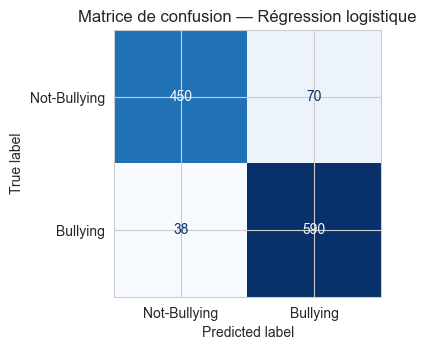

In [5]:
r = results["LogisticRegression"]
print(classification_report(y_test, r["y_pred"], target_names=["Not-Bullying", "Bullying"]))

fig, ax = plt.subplots(figsize=(4, 4))
cm = confusion_matrix(y_test, r["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=["Not-Bullying", "Bullying"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matrice de confusion — {r['name']}")
plt.tight_layout()
plt.show()

## Évaluation Modèle 2 — SVM linéaire

              precision    recall  f1-score   support

Not-Bullying       0.92      0.89      0.90       520
    Bullying       0.91      0.94      0.92       628

    accuracy                           0.91      1148
   macro avg       0.91      0.91      0.91      1148
weighted avg       0.91      0.91      0.91      1148



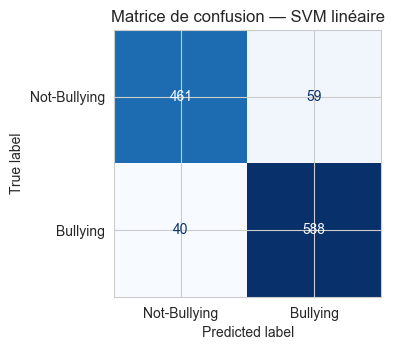

In [6]:
r = results["SVM"]
print(classification_report(y_test, r["y_pred"], target_names=["Not-Bullying", "Bullying"]))

fig, ax = plt.subplots(figsize=(4, 4))
cm = confusion_matrix(y_test, r["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=["Not-Bullying", "Bullying"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matrice de confusion — {r['name']}")
plt.tight_layout()
plt.show()

## Tableau comparatif

In [7]:
comparison = pd.DataFrame({
    name: {k: v for k, v in r.items() if k in ("accuracy", "precision", "recall", "f1", "roc_auc")}
    for name, r in results.items()
}).T
comparison.round(4)

,accuracy,precision,recall,f1,roc_auc
LogisticRegression,0.9059,0.8939,0.9395,0.9161,0.9643
SVM,0.9138,0.9088,0.9363,0.9224,0.9686


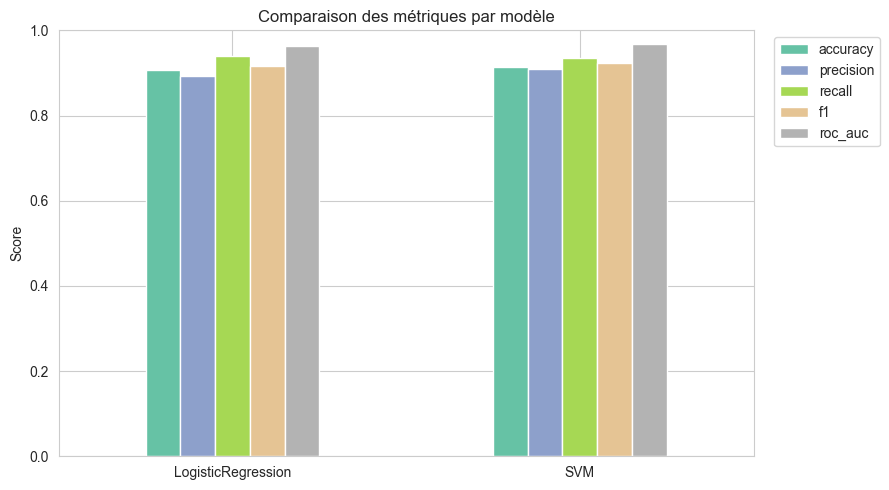

In [8]:
# Visualisation en barres groupées des 5 métriques
fig, ax = plt.subplots(figsize=(9, 5))
comparison.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_title("Comparaison des métriques par modèle")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

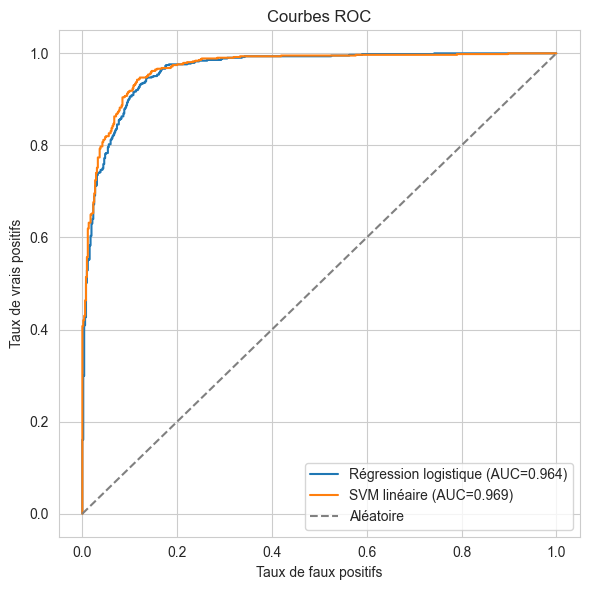

In [9]:
# Courbes ROC superposées
fig, ax = plt.subplots(figsize=(6, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"])
    ax.plot(fpr, tpr, label=f"{r['name']} (AUC={r['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Aléatoire")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC")
ax.legend()
plt.tight_layout()
plt.show()

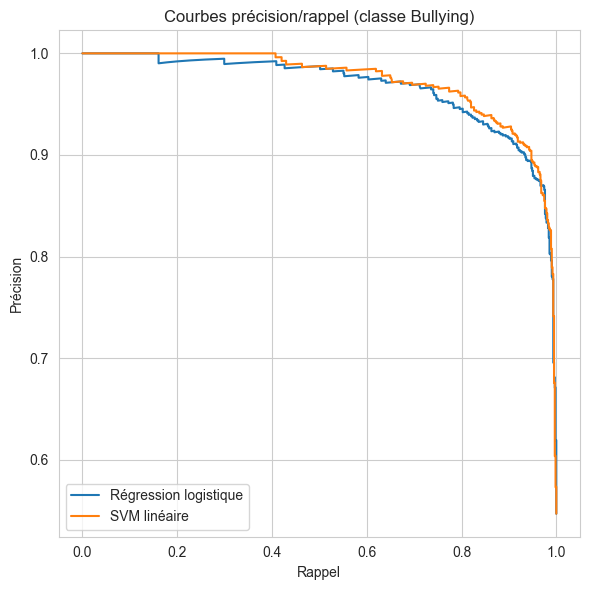

In [10]:
# Courbes précision/rappel superposées : plus informatives que la ROC ici,
# car les deux classes sont d'effectifs proches mais pas parfaitement égaux
fig, ax = plt.subplots(figsize=(6, 6))
for name, r in results.items():
    precision, recall, _ = precision_recall_curve(y_test, r["y_proba"])
    ax.plot(recall, precision, label=r["name"])
ax.set_xlabel("Rappel")
ax.set_ylabel("Précision")
ax.set_title("Courbes précision/rappel (classe Bullying)")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# Test de McNemar : les deux modèles se trompent-ils significativement
# différemment sur les mêmes exemples, ou leurs erreurs sont-elles comparables ?
pred_logreg = results["LogisticRegression"]["y_pred"]
pred_svm = results["SVM"]["y_pred"]
correct_logreg = (pred_logreg == y_test.values)
correct_svm = (pred_svm == y_test.values)

table = np.array([
    [np.sum(correct_logreg & correct_svm), np.sum(correct_logreg & ~correct_svm)],
    [np.sum(~correct_logreg & correct_svm), np.sum(~correct_logreg & ~correct_svm)],
])
print("Table de contingence (lignes=LogReg, colonnes=SVM ; 0=correct, 1=incorrect) :")
print(table)

b, c = table[0, 1], table[1, 0]
statistic = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0
p_value = 1 - chi2.cdf(statistic, df=1)

print(f"\nStatistique = {statistic:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("-> Différence statistiquement significative entre les deux modèles (p < 0.05).")
else:
    print("-> Pas de différence statistiquement significative entre les deux modèles (p >= 0.05).")


Table de contingence (lignes=LogReg, colonnes=SVM ; 0=correct, 1=incorrect) :
[[1023   17]
 [  26   82]]

Statistique = 1.4884, p-value = 0.2225
-> Pas de différence statistiquement significative entre les deux modèles (p >= 0.05).


In [12]:
# Analyse d'erreurs : messages sur lesquels les deux modèles sont en désaccord
disagreement = pd.DataFrame({
    "text": text_test.values,
    "true_label": y_test.map({v: k for k, v in LABEL_MAP.items()}).values,
    "pred_logreg": pd.Series(pred_logreg).map({v: k for k, v in LABEL_MAP.items()}).values,
    "pred_svm": pd.Series(pred_svm).map({v: k for k, v in LABEL_MAP.items()}).values,
})
disagreement = disagreement[disagreement["pred_logreg"] != disagreement["pred_svm"]]

print(f"Nombre de messages où les modèles sont en désaccord : {len(disagreement)}")
disagreement.head(15)

Nombre de messages où les modèles sont en désaccord : 43


,text,true_label,pred_logreg,pred_svm
7,your cooking always leaves me craving for more it's simply delicious,Not-Bullying,Not-Bullying,Bullying
17,your videos are like comedy gold nuggets in the youtube mine,Bullying,Not-Bullying,Bullying
19,she loves flower,Not-Bullying,Bullying,Not-Bullying
25,what a plenitude of magnificence,Not-Bullying,Bullying,Not-Bullying
33,continue what you have learned in the classroom of the world make it up from zero to hero,Bullying,Not-Bullying,Bullying
35,i love the way you taste,Bullying,Not-Bullying,Bullying
45,this is comedy gold and i'm here for it,Bullying,Not-Bullying,Bullying
67,women are so oversensitive,Bullying,Bullying,Not-Bullying
82,starting something new can be intimidating but i have faith in your abilities,Not-Bullying,Bullying,Not-Bullying
176,in the tapestry of life you're one of the most colorful threads,Not-Bullying,Bullying,Not-Bullying


### Conclusion

- Les deux modèles obtiennent des performances très proches (~91% d'accuracy, F1 ~0.92),
  ce qui est cohérent : sur du TF-IDF, régression logistique et SVM linéaire sont deux
  frontières de décision linéaires dans le même espace de features.
- Le **SVM linéaire** obtient une meilleure precision et un meilleur F1, avec un recall
  quasi identique à la régression logistique — il commet légèrement moins de faux positifs.
- Le test de McNemar indique si cet écart est significatif ou s'il tient au bruit
  d'échantillonnage (voir p-value ci-dessus).
- **Recommandation** : déployer le **SVM linéaire calibré** comme modèle principal dans
  l'API (meilleur F1/precision), en gardant la régression logistique disponible comme
  modèle secondaire pour comparaison (`model_used` dans la réponse de l'API).